# Activity 2: Simple House Price Prediction

## Step 1 & 2: Select, load, and inspect dataset
Dataset selected: House Prices Dataset (Synthetic) containing features like Area, Bedrooms, and Age_years.

In [1]:
%pip install seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('house_prices.csv')

# Handling missing values in the input feature
df['Area_sqft'] = df['Area_sqft'].fillna(df['Area_sqft'].median())

display(df.head())
print(f'Rows: {df.shape[0]}, Columns: {df.shape[1]}')

,House_ID,Area_sqft,Bedrooms,Age_years,Price
0,2001,2028.684448,3.0,11.367865,458396.800987
1,2002,3784.287710,1.0,17.083725,618203.747079
2,2003,1024.095058,3.0,19.045476,266987.764780
3,2004,830.353388,3.0,17.316088,246438.230521
4,2005,968.588275,3.0,11.952767,282069.692236


Rows: 300, Columns: 5


## Step 3: Select input features and target
Feature (X): `Area_sqft` (Larger areas generally correlate with higher prices).
Target (y): `Price` (Continuous numerical target).

In [3]:
X = df[['Area_sqft']]  # Using 2D array for scikit-learn
y = df['Price']

## Step 4: Visualise the relationship

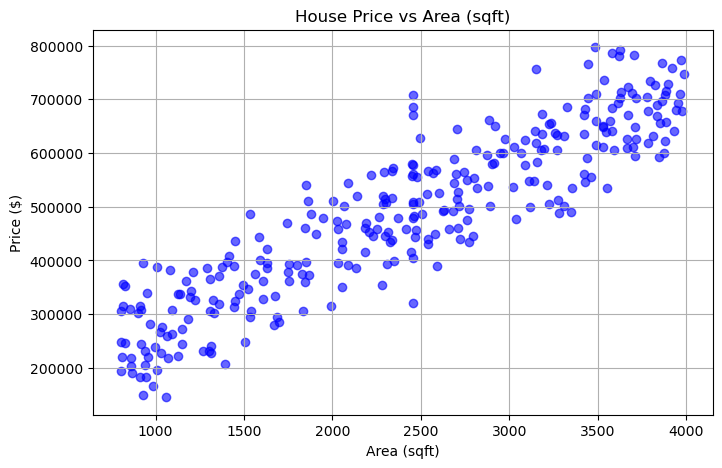

In [4]:
plt.figure(figsize=(8,5))
plt.scatter(X, y, alpha=0.6, color='blue')
plt.title('House Price vs Area (sqft)')
plt.xlabel('Area (sqft)')
plt.ylabel('Price ($)')
plt.grid(True)
plt.show()
# Observation: There is a visible positive linear relationship. However, correlation does not imply causation.

## Step 5: Split the data
Splitting 80% for training and 20% for testing so we evaluate on unseen data.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Training samples: {len(X_train)}, Testing samples: {len(X_test)}')

Training samples: 240, Testing samples: 60


## Step 6: Train Linear Regression

In [6]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f'Intercept (c): {model.intercept_:.2f}')
print(f'Coefficient (m): {model.coef_[0]:.2f}')
print(f'\nModel Equation: Price = {model.intercept_:.2f} + ({model.coef_[0]:.2f} * Area_sqft)')

Intercept (c): 133320.08
Coefficient (m): 146.40

Model Equation: Price = 133320.08 + (146.40 * Area_sqft)


## Step 7: Generate predictions

In [7]:
y_pred = model.predict(X_test)
results = pd.DataFrame({'Actual Price': y_test.values, 'Predicted Price': y_pred})
results['Difference'] = results['Actual Price'] - results['Predicted Price']
display(results.head(10))

,Actual Price,Predicted Price,Difference
0,400561.649038,366409.417157,34152.231881
1,453251.680068,455921.307266,-2669.627198
2,316042.513531,424638.925723,-108596.412192
3,279209.082214,377721.899394,-98512.817180
4,228099.778048,284366.832592,-56267.054543
5,492080.538489,517900.424009,-25819.885520
6,625271.383762,677621.277206,-52349.893444
7,316189.185132,252851.420651,63337.764481
8,382431.930378,291922.133482,90509.796896
9,654985.629695,606532.649704,48452.979992


## Step 8: Evaluate the model

In [8]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f'Mean Absolute Error (MAE): {mae:,.2f}')
print(f'Mean Squared Error (MSE): {mse:,.2f}')
print(f'Root Mean Squared Error (RMSE): {rmse:,.2f}')
print(f'R-squared (R2): {r2:.3f}')

Mean Absolute Error (MAE): 57,425.36
Mean Squared Error (MSE): 4,943,579,512.29
Root Mean Squared Error (RMSE): 70,310.59
R-squared (R2): 0.809


## Step 9: Visualise actual versus predicted values

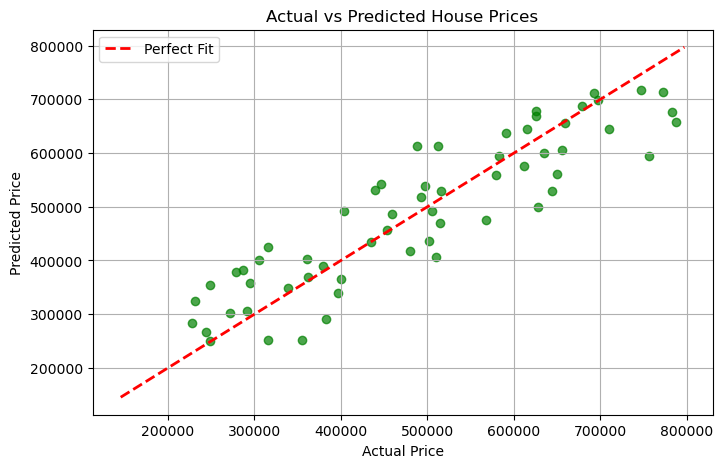

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred, alpha=0.7, color='green')
# Reference line for perfect prediction
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Fit')
plt.title('Actual vs Predicted House Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.grid(True)
plt.show()
# Observation: Predictions follow the reference line well, indicating the model performs reasonably on test data.

## Step 10: Predict a new example and conclude

In [10]:
new_house_area = [[1850]] # 1850 sqft
predicted_value = model.predict(new_house_area)
print(f'Predicted price for a 1850 sqft house: ${predicted_value[0]:,.2f}')

print('\nConclusion: The single-feature Linear Regression model captures the general pricing trend based on area. However, it simplifies the problem. In reality, factors like location, age, and number of bedrooms significantly affect the price, which would require a multiple regression model to capture fully.')

/lib/python3.14/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Predicted price for a 1850 sqft house: $404,162.19

Conclusion: The single-feature Linear Regression model captures the general pricing trend based on area. However, it simplifies the problem. In reality, factors like location, age, and number of bedrooms significantly affect the price, which would require a multiple regression model to capture fully.
